# 1. Cleaning

In [11]:
import numpy as np
import pandas as pd


In [12]:
df = pd.read_csv('loan_logreg1.csv', encoding = 'utf-8')

In [13]:
pd.set_option('display.max_columns', None)
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303638 entries, 0 to 1303637
Data columns (total 52 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   is_default                   1303638 non-null  int64  
 1   loan_amnt                    1303638 non-null  int64  
 2   is_term_sixty                1303638 non-null  int64  
 3   purpose                      1303638 non-null  object 
 4   int_rate                     1303638 non-null  float64
 5   grade                        1303638 non-null  int64  
 6   is_whole_offer               1303638 non-null  int64  
 7   is_joint_application         1303638 non-null  int64  
 8   emp_length                   1228181 non-null  float64
 9   home_ownership               1303638 non-null  object 
 10  annual_inc                   1303638 non-null  int64  
 11  verification_status          1303638 non-null  object 
 12  verif_status                 1303638 non-n

In [14]:
df = df.drop(columns=['verification_status'])

In [15]:
s = df["emp_length"].value_counts(normalize=True)
missing = df['emp_length'].isnull()
df.loc[missing,'emp_length'] = np.random.choice(s.index, size=len(df[missing]),p=s.values)

In [16]:
df.head(10)

,is_default,loan_amnt,is_term_sixty,purpose,int_rate,grade,is_whole_offer,is_joint_application,emp_length,home_ownership,annual_inc,verif_status,addr_state,delinq_2yrs,inq_last_6mths,pub_rec,pub_rec_bankruptcies,total_acc,mort_acc,dti,open_acc,revol_bal,revol_util,acc_now_delinq,tot_coll_amt,tot_cur_bal,mths_since_last_delinq,mths_since_last_record,mths_since_recent_inq,mths_since_recent_bc_dlq,mths_since_last_major_derog,mths_since_rcnt_il,all_util,avg_cur_bal,bc_open_to_buy,bc_util,il_util,inq_fi,inq_last_12m,pct_tl_nvr_dlq,tax_liens,tot_hi_cred_lim,total_bal_il,total_cu_tl,total_il_high_credit_limit,total_rev_hi_lim,num_actv_bc_tl,num_bc_tl,num_sats,num_tl_op_past_12m,credit_hist_months
0,0,30000,0,debt_consolidation,22.35,4,1,1,5.0,MORTGAGE,100000,1,CA,0,0,1,1,19,1,30.46,11,15603,37.0,0,0,472330,51.0,84.0,8,NaN,NaN,2,60,42939,15181,46.9,75,1,3,89.5,0,527120,82850,1,101984,42200,3,5,11,2,83
1,0,40000,1,credit_card,16.14,5,1,1,0.0,MORTGAGE,45000,2,OH,0,0,0,0,37,1,50.53,18,34971,64.5,0,0,271068,NaN,NaN,9,NaN,NaN,5,75,15059,14930,67.3,87,4,4,100.0,0,344802,126749,2,167965,54200,7,7,18,4,114
2,0,20000,0,credit_card,7.56,7,1,1,10.0,MORTGAGE,100000,0,WA,0,0,0,0,19,5,18.92,9,25416,29.9,0,0,515779,48.0,NaN,13,NaN,NaN,13,39,57309,59684,29.9,71,2,0,94.7,0,622183,46153,2,74833,85100,5,6,9,1,238
3,0,4500,0,credit_card,11.31,6,1,0,10.0,RENT,38500,0,TX,0,0,0,0,25,0,4.64,12,4472,15.3,0,306,29137,25.0,NaN,6,NaN,25.0,3,54,2428,10735,28.9,100,0,3,91.7,0,53795,24665,3,24595,29200,3,6,12,4,180
4,0,8425,0,credit_card,27.27,3,1,1,3.0,MORTGAGE,450000,2,MA,0,0,0,0,37,4,12.37,21,36812,65.7,0,0,690320,NaN,NaN,4,NaN,NaN,12,68,34516,11632,74.6,70,7,5,100.0,0,768304,152382,0,189054,56000,6,10,21,2,254
5,0,20000,1,debt_consolidation,17.97,4,1,0,4.0,RENT,57000,0,WA,0,0,0,0,16,1,22.18,10,33356,45.9,0,0,33356,NaN,NaN,17,NaN,NaN,78,46,3336,32170,50.4,0,0,0,100.0,0,72700,0,0,0,72700,4,9,10,2,284
6,0,6600,0,credit_card,11.31,6,0,0,10.0,RENT,45000,0,TX,0,0,0,0,13,0,16.21,6,6167,58.2,0,0,26836,NaN,NaN,0,NaN,NaN,27,70,4473,4433,58.2,74,0,0,84.6,0,38607,20669,1,28007,10600,2,4,6,0,116
7,0,2500,0,other,13.56,5,0,0,5.0,RENT,42000,0,PA,0,0,0,0,6,0,15.09,3,3319,31.6,0,0,18649,53.0,NaN,12,NaN,NaN,22,57,6216,7181,31.6,69,2,1,83.3,0,32582,15330,0,22082,10500,2,2,3,1,177
8,0,4000,0,house,17.97,4,1,0,5.0,MORTGAGE,60000,1,TX,0,1,0,0,18,2,19.10,11,382,7.3,0,0,106556,38.0,NaN,2,NaN,38.0,1,72,9687,3818,9.1,77,3,3,88.2,0,127200,45868,0,59474,5200,2,5,11,4,138
9,0,2700,0,credit_card,8.19,7,0,0,4.0,OWN,24000,0,MI,0,0,1,1,28,0,24.95,21,2696,36.4,0,449,75363,NaN,94.0,18,NaN,NaN,16,97,3589,3304,44.9,103,1,0,100.0,0,78017,72667,0,70617,7400,1,4,21,0,194


In [17]:
from scipy.stats import mannwhitneyu, chi2_contingency

isdef = df[df["is_default"] == 1]
non = df[df["is_default"] == 0]

In [18]:
print(len(isdef), len(non))

261686 1041952


In [27]:
bin_features = ["is_term_sixty", "is_whole_offer", "is_joint_application"]
cat_features = ["purpose", "home_ownership", "addr_state"]
num_features = [col for col in df.columns if col not in bin_features + cat_features]

In [ ]:
def rank_biserial(g1, g2, u_stat):
    # effect size for mann-whitney, ranges -1 to 1
    return 1 - (2 * u_stat) / (len(g1) * len(g2))


def cramers_v(chi2_stat, n, shape):
    min_dim = min(shape[0] - 1, shape[1] - 1)
    return np.sqrt(chi2_stat / (n * min_dim))


def run_mwu(features):
    out = []
    for f in features:
        if f not in df.columns:
            continue
        u, p = mannwhitneyu(isdef[f], non[f], nan_policy='omit', alternative="two-sided")
        out.append({
            "feature":   f,
            "isdef_mean": round(isdef[f].mean(), 4),
            "non_mean": round(non[f].mean(), 4),
            "U":         round(u, 1),
            "rank_biserial": round(rank_biserial(isdef[f], non[f], u), 4),
            "p_value":   p,
        })
    return pd.DataFrame(out)


def run_chi2_bin(features):
    n_total = len(df)
    out = []
    for f in features:
        if f not in df.columns:
            continue
        table = pd.crosstab(df["is_default"], df[f])
        chi2, p, dof, _ = chi2_contingency(table)
        out.append({
            "feature":     f,
            "isdef_rate":    round(isdef[f].mean(), 4),   # proportion flagged in isdef
            "non_rate":    round(non[f].mean(), 4),
            "chi2":        round(chi2, 2),
            "cramers_v":  round(cramers_v(chi2, n_total, table.shape), 4),
            "p_value":     f'{p:.3e}',
        })
    return pd.DataFrame(out)

def run_chi2_cat(features):
    n_total = len(df)
    out = []
    for f in features:
        if f not in df.columns:
            continue
        table = pd.crosstab(df["is_default"], df[f])
        chi2, p, dof, _ = chi2_contingency(table)
        out.append({
            "feature":    f,
            "chi2":       round(chi2, 2),
            "cramers_v":  round(cramers_v(chi2, n_total, table.shape), 4),
            "p_value":    f'{p:.3e}',
            "n_levels":   table.shape[1],
        })
    return pd.DataFrame(out)

In [ ]:
pd.reset_option('float_format')

print("1. continuous features (Mann-Whitney U)")
cont_results = run_mwu(num_features)
print(cont_results.to_string(index=False), "\n")

print("2. binary features (Chi-squared)")
bin_results = run_chi2_bin(bin_features)
print(bin_results)

print("3. categorical features (Chi-squared)")
cat_results = run_chi2_cat(cat_features)
print(cat_results)

1. continuous features (Mann-Whitney U)
                    feature  isdef_mean    non_mean            U  rank_biserial       p_value
                 is_default      1.0000      0.0000 2.726643e+11        -1.0000  0.000000e+00
                  loan_amnt  15549.0091  14132.4937 1.501466e+11        -0.1013  0.000000e+00
                   int_rate     15.7122     12.6408 1.862104e+11        -0.3659  0.000000e+00
                      grade      4.5709      5.4187 8.720939e+10         0.3603  0.000000e+00
                 emp_length      5.8706      5.9941 1.336671e+11         0.0195  1.339240e-56
                 annual_inc  70327.2754  77623.3265 1.230506e+11         0.0974  0.000000e+00
               verif_status      1.1524      0.9766 1.529311e+11        -0.1218  0.000000e+00
                delinq_2yrs      0.3527      0.3088 1.389997e+11        -0.0196 8.441298e-113
             inq_last_6mths      0.7813      0.6284 1.476539e+11        -0.0830  0.000000e+00
                    

In [33]:
# bonferroni correction
n_tests = len(cont_results) + len(bin_results) + len(cat_results)
alpha_adj = 0.05 / n_tests
print(f"tests run: {n_tests}")
print(f"bonferroni-adjusted alpha: {round(alpha_adj, 5)}")
print("(features below this p-value are significant after correction)")

tests run: 51
bonferroni-adjusted alpha: 0.00098
(features below this p-value are significant after correction)


In [34]:
def level_summary(df, f, target="is_default"):
    table = pd.crosstab(df[f], df[target])          # columns: 0, 1
    chi2, p, dof, expected = chi2_contingency(table)
    N = table.values.sum()
    row_tot = table.sum(axis=1).values
    col_tot = table.sum(axis=0).values

    obs_def = table[1].values
    exp_def = expected[:, 1]
    adj_resid = (obs_def - exp_def) / np.sqrt(
        exp_def * (1 - row_tot / N) * (1 - col_tot[1] / N)
    )

    overall = df[target].mean()
    out = pd.DataFrame({
        "n": row_tot,
        "default_rate": obs_def / row_tot,
        "lift": (obs_def / row_tot) / overall,
        "adj_resid": adj_resid,
    }, index=table.index)
    return out.sort_values("default_rate", ascending=False).round(4)


In [35]:
for f in ["purpose", "home_ownership", "addr_state"]:
    display(level_summary(df, f))

,n,default_rate,lift,adj_resid
purpose,,,,
small_business,15010,0.2975,1.4819,29.7594
renewable_energy,911,0.2371,1.1812,2.7413
moving,9173,0.2345,1.1682,8.1003
medical,15024,0.2191,1.0916,5.6574
house,6967,0.2172,1.0819,3.4333
debt_consolidation,757610,0.2126,1.0590,39.7942
other,74937,0.2117,1.0548,7.7454
vacation,8732,0.1924,0.9585,-1.9521
major_purchase,28328,0.1872,0.9327,-5.7353


,n,default_rate,lift,adj_resid
home_ownership,,,,
RENT,517821,0.2335,1.1632,75.8057
OWN,139849,0.2075,1.0336,6.6657
ANY,267,0.1948,0.9702,-0.2439
OTHER,144,0.1875,0.9341,-0.3965
MORTGAGE,645509,0.1730,0.8618,-78.2890
NONE,48,0.1458,0.7265,-0.9496


,n,default_rate,lift,adj_resid
addr_state,,,,
MS,6316,0.2620,1.3054,12.1917
NE,3422,0.2542,1.2665,7.8239
AR,9708,0.2417,1.2039,10.1037
AL,16130,0.2374,1.1826,11.6929
OK,11846,0.2371,1.1813,9.9336
LA,15021,0.2341,1.1661,10.2598
NY,106387,0.2215,1.1033,17.6224
NV,19652,0.2205,1.0986,6.9832
IN,21020,0.2161,1.0767,5.6169


In [ ]:
df

,is_default,loan_amnt,is_term_sixty,purpose,int_rate,grade,is_whole_offer,is_joint_application,emp_length,home_ownership,annual_inc,verif_status,addr_state,delinq_2yrs,inq_last_6mths,pub_rec,pub_rec_bankruptcies,total_acc,mort_acc,dti,open_acc,revol_bal,revol_util,acc_now_delinq,tot_coll_amt,tot_cur_bal,mths_since_last_delinq,mths_since_last_record,mths_since_recent_inq,mths_since_recent_bc_dlq,mths_since_last_major_derog,mths_since_rcnt_il,all_util,avg_cur_bal,bc_open_to_buy,bc_util,il_util,inq_fi,inq_last_12m,pct_tl_nvr_dlq,tax_liens,tot_hi_cred_lim,total_bal_il,total_cu_tl,total_il_high_credit_limit,total_rev_hi_lim,num_actv_bc_tl,num_bc_tl,num_sats,num_tl_op_past_12m,credit_hist_months
0,0,30000,0,debt_consolidation,22.35,4,1,1,5.0,MORTGAGE,100000,1,CA,0,0,1,1,19,1,30.46,11,15603,37.0,0,0,472330,51.0,84.0,8,NaN,NaN,2,60,42939,15181,46.9,75,1,3,89.5,0,527120,82850,1,101984,42200,3,5,11,2,83
1,0,40000,1,credit_card,16.14,5,1,1,0.0,MORTGAGE,45000,2,OH,0,0,0,0,37,1,50.53,18,34971,64.5,0,0,271068,NaN,NaN,9,NaN,NaN,5,75,15059,14930,67.3,87,4,4,100.0,0,344802,126749,2,167965,54200,7,7,18,4,114
2,0,20000,0,credit_card,7.56,7,1,1,10.0,MORTGAGE,100000,0,WA,0,0,0,0,19,5,18.92,9,25416,29.9,0,0,515779,48.0,NaN,13,NaN,NaN,13,39,57309,59684,29.9,71,2,0,94.7,0,622183,46153,2,74833,85100,5,6,9,1,238
3,0,4500,0,credit_card,11.31,6,1,0,10.0,RENT,38500,0,TX,0,0,0,0,25,0,4.64,12,4472,15.3,0,306,29137,25.0,NaN,6,NaN,25.0,3,54,2428,10735,28.9,100,0,3,91.7,0,53795,24665,3,24595,29200,3,6,12,4,180
4,0,8425,0,credit_card,27.27,3,1,1,3.0,MORTGAGE,450000,2,MA,0,0,0,0,37,4,12.37,21,36812,65.7,0,0,690320,NaN,NaN,4,NaN,NaN,12,68,34516,11632,74.6,70,7,5,100.0,0,768304,152382,0,189054,56000,6,10,21,2,254
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1303633,1,30000,1,debt_consolidation,17.09,4,0,0,2.0,RENT,80000,0,NY,0,1,0,0,69,0,23.22,21,19224,30.8,0,0,196622,46.0,NaN,2,NaN,61.0,8,61,9831,31294,36.5,101,0,1,54.9,0,231009,177398,0,168609,62400,5,8,21,3,190
1303634,1,18000,1,debt_consolidation,30.65,2,1,0,10.0,MORTGAGE,77000,2,TX,0,1,0,0,15,1,8.08,9,10100,45.1,0,265,324621,38.0,NaN,4,38.0,NaN,4,59,36069,7083,48.7,98,0,7,93.3,0,338546,6925,3,7058,22400,3,4,9,5,157
1303635,0,17950,1,debt_consolidation,30.17,2,0,0,10.0,MORTGAGE,53758,1,IL,0,1,1,1,24,3,33.24,11,5959,35.9,0,0,156247,NaN,80.0,0,NaN,NaN,11,46,15625,1587,60.3,49,1,2,100.0,0,203667,30693,1,63002,16600,1,4,11,2,202
1303636,0,15000,1,debt_consolidation,16.02,5,1,0,0.0,RENT,85000,2,NY,0,3,0,0,87,1,14.66,19,6988,24.8,0,4199,239081,36.0,NaN,0,36.0,36.0,4,52,17077,17477,23.7,70,1,7,89.0,0,267274,232093,2,239074,28200,4,17,19,7,199


# 2. EDA

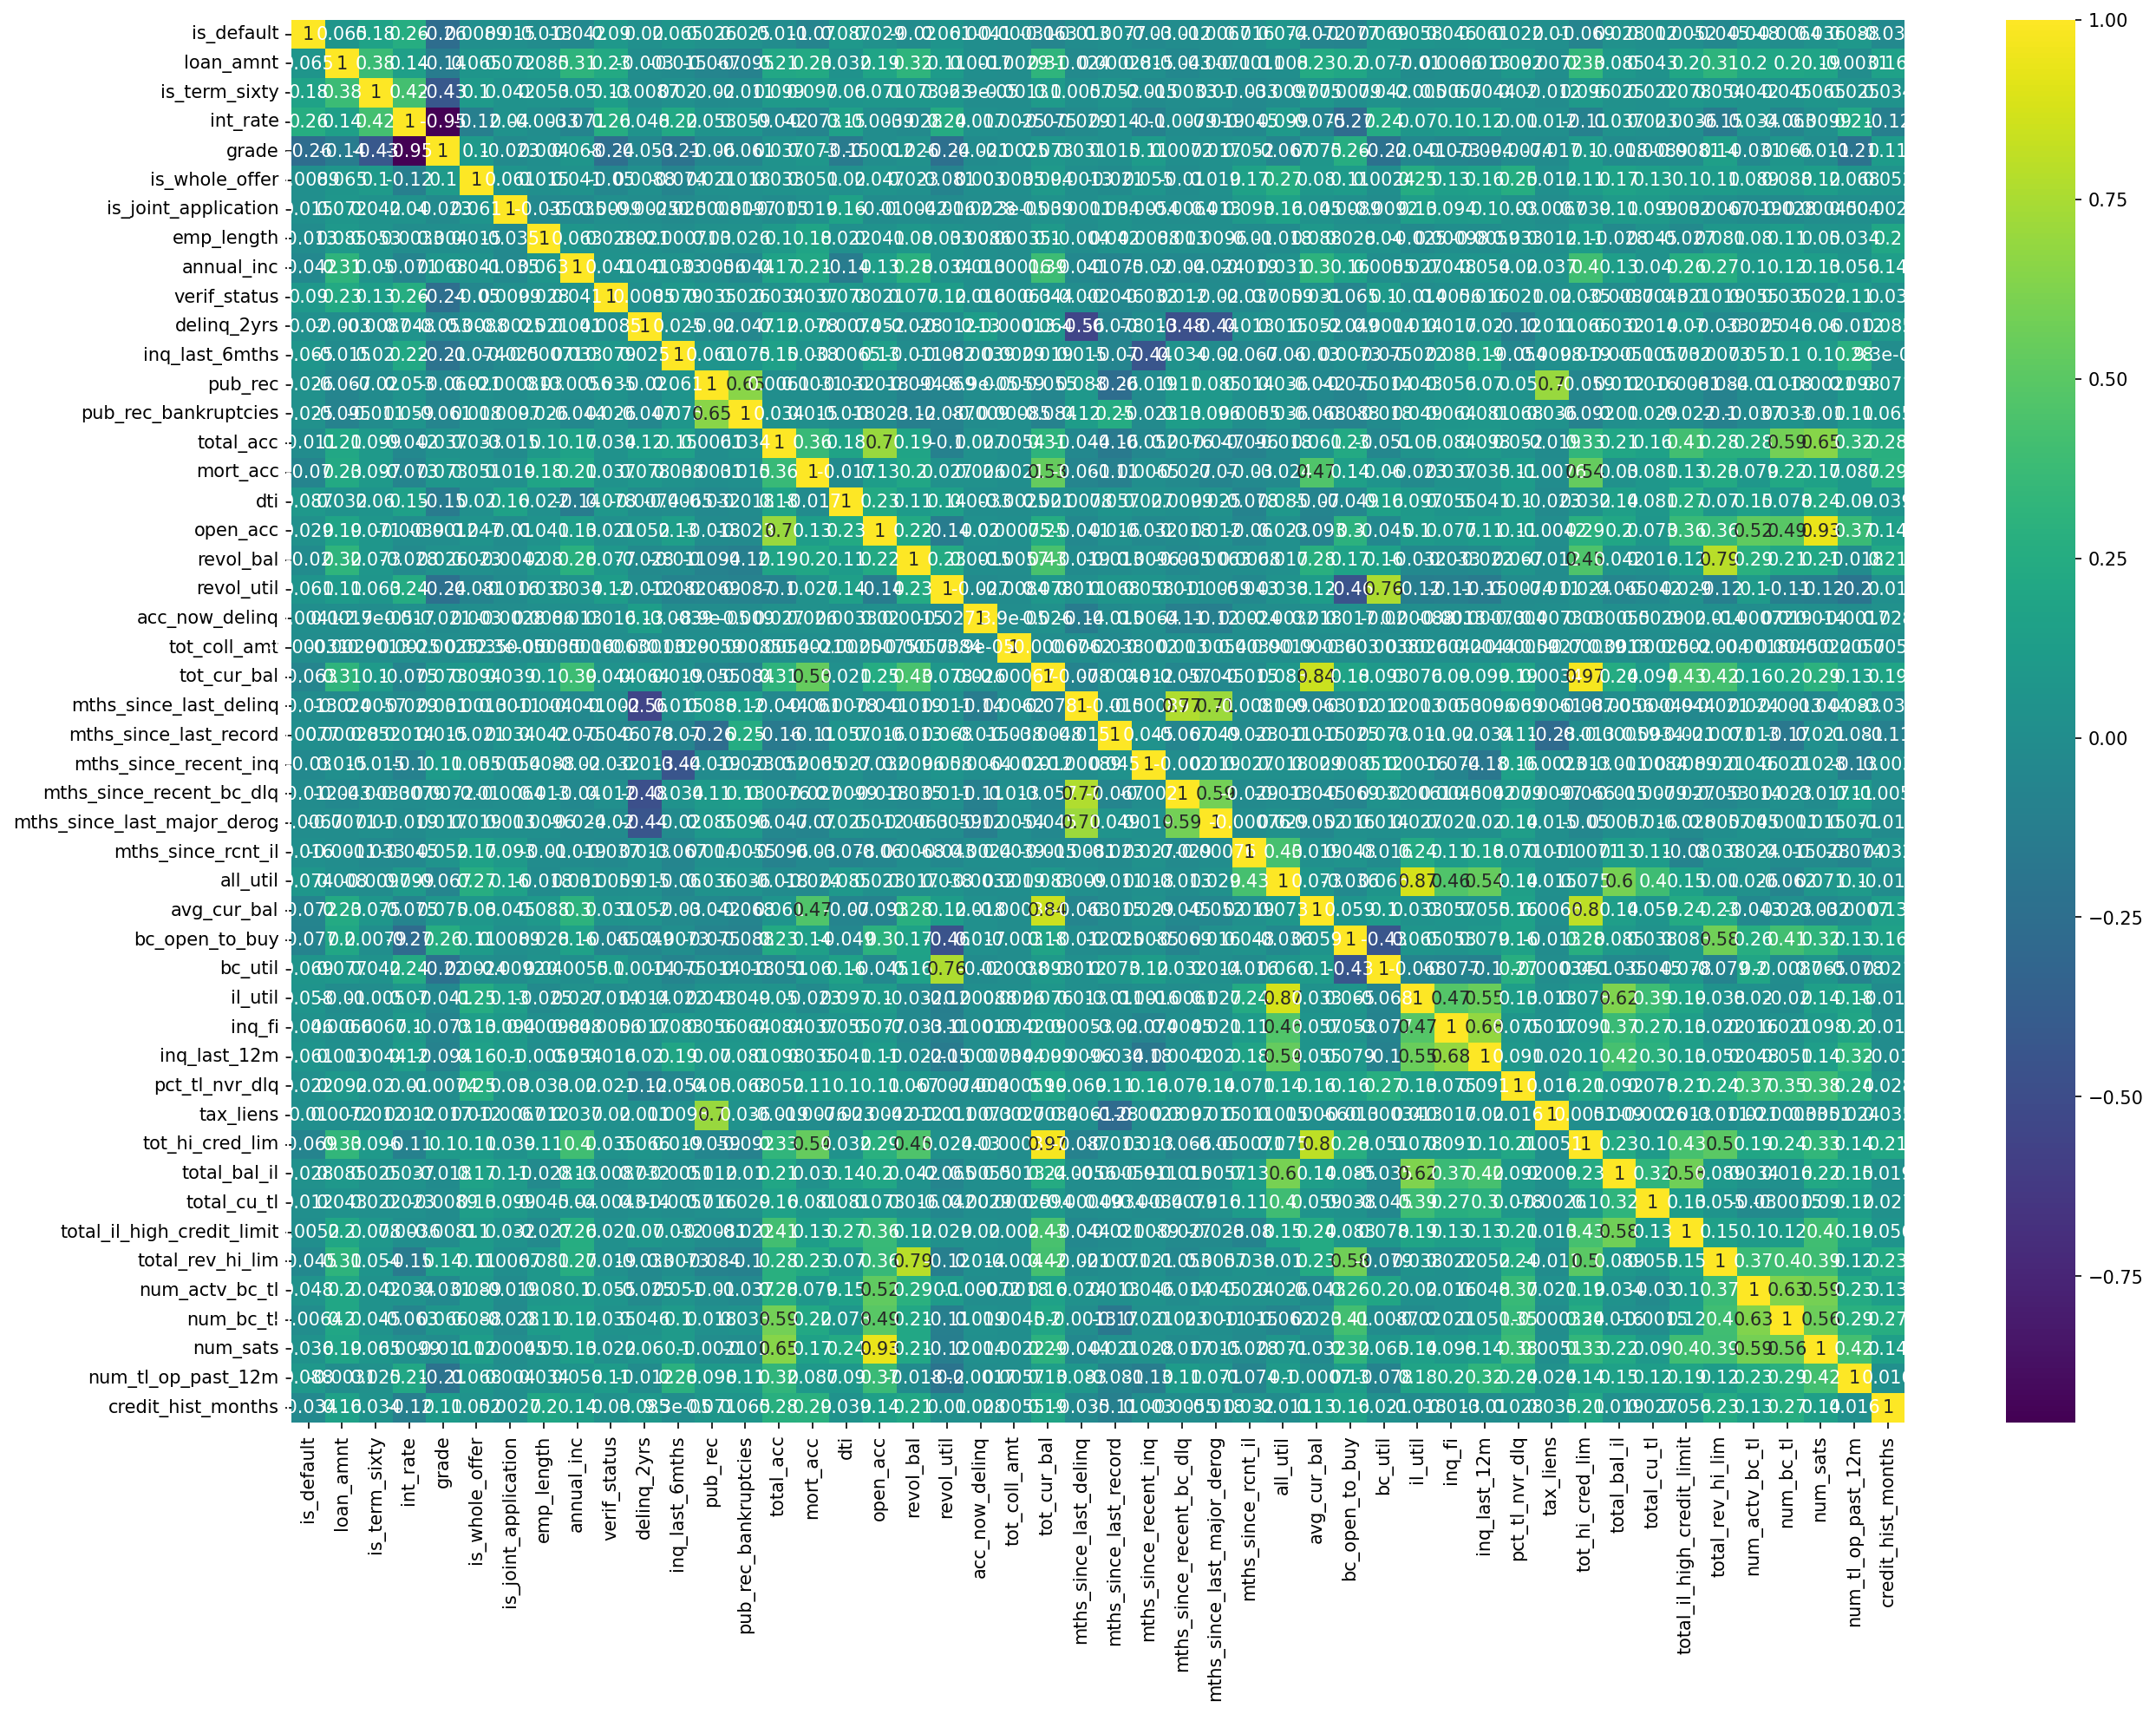

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(20,14), dpi= 150)
sns.heatmap(df.loc[:, [col for col in df.columns if col not in cat_features]].corr(), annot=True, cmap='viridis')
plt.savefig("correlation_heatmap.png", dpi=150)

# 3. Modelling

In [58]:
counts = df['addr_state'].value_counts()
idx = counts[counts.lt(5000)].index

df.loc[df['addr_state'].isin(idx), 'addr_state'] = 'Others'

df = df.drop(columns=['tot_hi_cred_lim', 'grade', 'avg_cur_bal', 'num_sats'])

In [59]:
df['addr_state'].value_counts()

addr_state
CA        191036
TX        106677
NY        106387
FL         92620
IL         50030
NJ         46885
PA         44117
OH         42438
GA         42032
VA         36852
NC         36615
Others     35068
MI         34128
AZ         31716
MD         30224
MA         30007
CO         28859
WA         28362
MN         23242
IN         21020
MO         20563
TN         19667
NV         19652
CT         19063
WI         17138
AL         16130
OR         15965
SC         15477
LA         15021
KY         12439
OK         11846
KS         10892
UT          9785
AR          9708
NM          7158
HI          6568
MS          6316
NH          6243
RI          5692
Name: count, dtype: int64

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303638 entries, 0 to 1303637
Data columns (total 47 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   is_default                   1303638 non-null  int64  
 1   loan_amnt                    1303638 non-null  int64  
 2   is_term_sixty                1303638 non-null  int64  
 3   purpose                      1303638 non-null  object 
 4   int_rate                     1303638 non-null  float64
 5   is_whole_offer               1303638 non-null  int64  
 6   is_joint_application         1303638 non-null  int64  
 7   emp_length                   1303638 non-null  float64
 8   home_ownership               1303638 non-null  object 
 9   annual_inc                   1303638 non-null  int64  
 10  verif_status                 1303638 non-null  int64  
 11  addr_state                   1303638 non-null  object 
 12  delinq_2yrs                  1303638 non-n

In [61]:

from sklearn.preprocessing import OneHotEncoder

categorical_columns = df.select_dtypes(include=['object']).columns

encoder = OneHotEncoder(sparse_output=False)

encoded_data = encoder.fit_transform(df[categorical_columns])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categorical_columns)
)

df1 = pd.concat(
    [df.drop(columns=categorical_columns), encoded_df],
    axis=1
)

In [62]:
# sampling to drastically reduce computing
df2 = df1.sample(n=50000, random_state=42)
df2

,is_default,loan_amnt,is_term_sixty,int_rate,is_whole_offer,is_joint_application,emp_length,annual_inc,verif_status,delinq_2yrs,inq_last_6mths,pub_rec,pub_rec_bankruptcies,total_acc,mort_acc,dti,open_acc,revol_bal,revol_util,acc_now_delinq,tot_coll_amt,tot_cur_bal,mths_since_last_delinq,mths_since_last_record,mths_since_recent_inq,mths_since_recent_bc_dlq,mths_since_last_major_derog,mths_since_rcnt_il,all_util,bc_open_to_buy,bc_util,il_util,inq_fi,inq_last_12m,pct_tl_nvr_dlq,tax_liens,total_bal_il,total_cu_tl,total_il_high_credit_limit,total_rev_hi_lim,num_actv_bc_tl,num_bc_tl,num_tl_op_past_12m,credit_hist_months,purpose_car,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_house,purpose_major_purchase,purpose_medical,purpose_moving,purpose_other,purpose_renewable_energy,purpose_small_business,purpose_vacation,purpose_wedding,home_ownership_ANY,home_ownership_MORTGAGE,home_ownership_NONE,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,addr_state_AL,addr_state_AR,addr_state_AZ,addr_state_CA,addr_state_CO,addr_state_CT,addr_state_FL,addr_state_GA,addr_state_HI,addr_state_IL,addr_state_IN,addr_state_KS,addr_state_KY,addr_state_LA,addr_state_MA,addr_state_MD,addr_state_MI,addr_state_MN,addr_state_MO,addr_state_MS,addr_state_NC,addr_state_NH,addr_state_NJ,addr_state_NM,addr_state_NV,addr_state_NY,addr_state_OH,addr_state_OK,addr_state_OR,addr_state_Others,addr_state_PA,addr_state_RI,addr_state_SC,addr_state_TN,addr_state_TX,addr_state_UT,addr_state_VA,addr_state_WA,addr_state_WI
896352,0,10000,0,15.88,0,0,10.0,78000,0,1,1,0,0,30,0,5.89,17,11656,23.6,0,0,11656,9.0,NaN,4,9.0,43.0,0,0,31078,27.2,0,0,0,93.0,0,0,0,0,53300,5,19,1,162,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1186414,0,3600,0,11.99,1,0,2.0,86000,0,1,1,0,0,60,4,21.06,22,18069,38.7,0,0,262748,22.0,NaN,3,NaN,32.0,0,0,22031,39.8,0,0,0,98.3,0,0,0,54124,46700,6,22,4,302,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1267756,0,16000,0,12.87,0,0,10.0,65000,2,0,0,0,0,15,0,11.52,5,7290,93.5,0,0,0,NaN,NaN,0,NaN,NaN,0,0,0,0.0,0,0,0,0.0,0,0,0,0,0,0,0,0,156,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
101017,1,6800,0,12.79,1,0,6.0,36000,1,2,1,0,0,44,0,6.03,17,2953,43.4,0,0,120528,18.0,NaN,4,23.0,23.0,6,96,904,46.8,101,1,1,85.0,0,117575,0,114210,6800,2,7,3,226,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
82212,0,5075,0,23.99,0,0,3.0,52000,1,1,1,3,0,28,6,22.18,10,6360,46.8,0,9473,121734,9.0,62.0,5,9.0,44.0,6,50,2235,67.6,51,0,2,71.4,0,11189,0,21829,13600,2,9,5,468,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1253310,0,5525,0,11.11,0,0,1.0,46800,0,0,2,0,0,11,0,14.59,8,7120,57.9,0,0

In [63]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

x = df2.drop(columns=['is_default'])
y = df2['is_default']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y, random_state=42)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled  = scaler.transform(x_test)

x_train_scaled = pd.DataFrame(x_train_scaled, columns=x.columns, index=x_train.index)
x_test_scaled  = pd.DataFrame(x_test_scaled,  columns=x.columns, index=x_test.index)

In [64]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\n[A] scale_pos_weight = {spw:.3f}")



[A] scale_pos_weight = 3.943


In [65]:
from xgboost import XGBClassifier

In [ ]:

# # hyperparameter tuning ~20 minutes runtime for 2500 fits

# param_grid = {
#     'n_estimators': [200, 300],
#     'max_depth': [3, 5, 7],             # very important
#     'min_child_weight': [3, 5, 7],
#     'subsample': [0.6, 0.8, 1.0],
#     'colsample_bytree': [0.6, 0.8, 1.0],
#     'learning_rate': [0.01, 0.1, 0.3]   # very important
# }

# # Create XGBoost classifier
# xgb = XGBClassifier(random_state=42) # default values

# # Perform grid search
# grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=5, n_jobs=-1, verbose=5, scoring='roc_auc')
# grid_search.fit(x_train, y_train)

# # print best parameters
# print(f"Best parameters: {grid_search.best_params_}")
# print(f"Best score: {grid_search.best_score_}")

In [66]:
parameters = dict(
    n_estimators=200,
    max_depth=5,
    min_child_weight=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8, 
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

model_a = XGBClassifier(scale_pos_weight=spw, **parameters)
model_a.fit(x_train_scaled, y_train)

# metrics
from sklearn.metrics import roc_auc_score, f1_score

for name, model in [("A (scale_pos_weight)", model_a)]:
    proba = model.predict_proba(x_test_scaled)[:, 1]
    pred  = model.predict(x_test_scaled)
    auc   = roc_auc_score(y_test, proba)
    f1    = f1_score(y_test, pred)
    print(f"  {name}: AUC={auc:.4f}, F1={f1:.4f}")


  A (scale_pos_weight): AUC=0.7189, F1=0.4415


In [67]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score

model = model_a

#predictions on the untouched test set
y_pred  = model.predict(x_test_scaled)
y_proba = model.predict_proba(x_test_scaled)[:, 1]

In [68]:
print(classification_report(y_test, y_pred, target_names=["non_default", "default"], digits=4))

              precision    recall  f1-score   support

 non_default     0.8829    0.6739    0.7644      7977
     default     0.3350    0.6476    0.4415      2023

    accuracy                         0.6686     10000
   macro avg     0.6089    0.6607    0.6030     10000
weighted avg     0.7721    0.6686    0.6991     10000



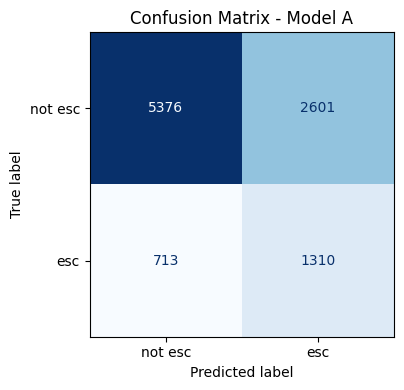

In [69]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["not esc", "esc"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - Model A")
plt.tight_layout()

plt.show()


waterfall for test row 3 (true positive)


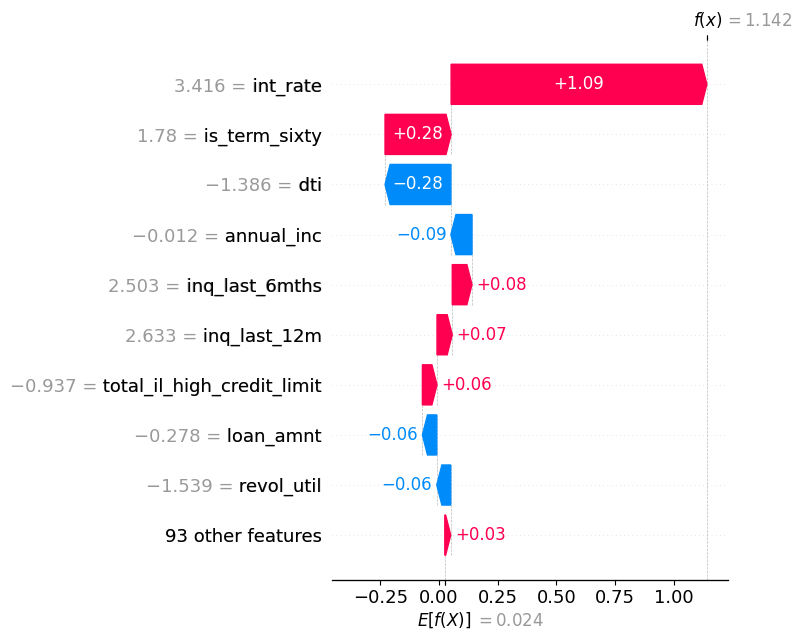

In [70]:
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(x_test_scaled)
tp_mask = (y_test.values == 1) & (y_pred == 1)
tp_idx  = np.where(tp_mask)[0][0] 

print(f"\nwaterfall for test row {tp_idx} (true positive)")
plt.figure()
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[tp_idx],
        base_values=explainer.expected_value,
        data=x_test_scaled.iloc[tp_idx],
        feature_names=list(x_test_scaled.columns),
    ),
    show=False,
)
plt.tight_layout()
plt.show()